# 05 Evaluation

We compare logistic regression, the neural network and the students' own confidence on the **test set**: students no model or setting was chosen with.
This is the only notebook that uses the test set.

In [ ]:
import sys
sys.path.append("..")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, accuracy_score, log_loss, brier_score_loss

from src.data import load_data, split_students

FIG = Path("../results/figures")        # figures for the report
FIG.mkdir(parents=True, exist_ok=True)

# 1. The data and the split
df = split_students(load_data())

# 2. The saved predictions from notebooks 03 and 04
lr = pd.read_csv("../results/preds_logreg.csv").rename(columns={"p_correct": "p_logreg"})
nn = pd.read_csv("../results/preds_nn.csv").rename(columns={"p_correct": "p_nn"})

# 3. One row per TEST answer: the true result, confidence, groups and both predictions
test = df[df["split"] == "test"][["AnswerId", "UserId", "IsCorrect", "Confidence", "Gender", "PremiumPupil"]]
test = test.merge(lr[["AnswerId", "p_logreg"]], on="AnswerId", how="left")
test = test.merge(nn[["AnswerId", "p_nn"]], on="AnswerId", how="left")

print("Test answers:          ", f"{len(test):,}")
print("Missing predictions:   ", test[["p_logreg", "p_nn"]].isna().sum().sum())
print("With a confidence rating:", f"{test['Confidence'].notna().sum():,}")
test.head()

Test answers:           204,832
Missing predictions:    0
With a confidence rating: 48,049


,AnswerId,UserId,IsCorrect,Confidence,Gender,PremiumPupil,p_logreg,p_nn
0,86628,6,1,50.0,0,NaN,0.614994,0.602814
1,68287,6,1,75.0,0,NaN,0.543380,0.482476
2,363638,6,1,100.0,0,NaN,0.801377,0.818326
3,987997,6,0,0.0,0,NaN,0.690769,0.724873
4,420311,6,0,0.0,0,NaN,0.264236,0.201190


## 1. Final scores on the test set
All choices were made on validation, so these are honest scores for new students.

In [14]:
y = test["IsCorrect"]
train_rate = df.loc[df["split"] == "train", "IsCorrect"].mean()   # share correct in training
majority = np.full(len(test), train_rate)                          # same guess for every answer

final = pd.DataFrame({
    "model":    ["Majority", "Logistic regression", "Neural network"],
    "AUC":      [roc_auc_score(y, majority), roc_auc_score(y, test["p_logreg"]), roc_auc_score(y, test["p_nn"])],
    "accuracy": [accuracy_score(y, majority >= 0.5), accuracy_score(y, test["p_logreg"] >= 0.5), accuracy_score(y, test["p_nn"] >= 0.5)],
    "log loss": [log_loss(y, majority), log_loss(y, test["p_logreg"]), log_loss(y, test["p_nn"])],
}).round(4)
final

,model,AUC,accuracy,log loss
0,Majority,0.5000,0.5321,0.6911
1,Logistic regression,0.7723,0.7045,0.5715
2,Neural network,0.7753,0.7083,0.5604


**Takeaway:** On new students, the neural network gets AUC 0.775 and 70.8% right, a little better than logistic regression (AUC 0.772, 70.5%). Both are far better than always guessing "correct" (53.2%). The test scores are only about 0.004 lower than on validation for both models, so our choices did not overfit the validation students.

## 2. Models vs. student confidence
On answers that have a confidence rating, we compare three ways to predict "will this answer be correct?": the student's own confidence (rating / 100), logistic regression and the neural network.
We use the **Brier score** (lower is better) instead of log loss, because a confidence of 0 or 100 would make log loss infinite.

In [15]:
# only answers with a confidence rating; turn the rating into a probability (75 -> 0.75)
rated = test[test["Confidence"].notna()].copy()
rated["p_conf"] = rated["Confidence"] / 100

print("Rated test answers:", f"{len(rated):,}")
print("Percent correct among rated:", round(rated["IsCorrect"].mean() * 100, 1))

y = rated["IsCorrect"]
vs_conf = pd.DataFrame({
    "predictor":   ["Student confidence", "Logistic regression", "Neural network"],
    "AUC":         [roc_auc_score(y, rated["p_conf"]), roc_auc_score(y, rated["p_logreg"]), roc_auc_score(y, rated["p_nn"])],
    "accuracy":    [accuracy_score(y, rated["p_conf"] >= 0.5), accuracy_score(y, rated["p_logreg"] >= 0.5), accuracy_score(y, rated["p_nn"] >= 0.5)],
    "Brier score": [brier_score_loss(y, rated["p_conf"]), brier_score_loss(y, rated["p_logreg"]), brier_score_loss(y, rated["p_nn"])],
}).round(4)
vs_conf

Rated test answers: 48,049
Percent correct among rated: 62.4


,predictor,AUC,accuracy,Brier score
0,Student confidence,0.6343,0.6618,0.2679
1,Logistic regression,0.7829,0.7242,0.1828
2,Neural network,0.7854,0.7227,0.1811


**Takeaway:** On the 48,049 rated test answers, both models are much better than the students' own confidence: 

AUC 0.785 (neural network) and 0.783 (logistic regression) vs. 0.634, and about 72% right vs. 66%. 

Confidence does rank answers a little (AUC above 0.5), but as a probability it is poor: its Brier score (0.268) is worse than always saying 50% (0.25). 

The models win even though students rate after choosing their answer. Rated answers are easier than average (62.4% correct vs. 53.2%), so this comparison covers only part of the students.

## 3. Calibration
Do the predicted percentages match reality? We sort answers into 10 groups by their predicted probability and compare the average prediction with the share actually correct.
**ECE** is the average gap between the two (0 = perfect). In the **reliability diagram**, a perfect predictor lies on the diagonal.

In [16]:
def calibration_table(y, prob):
    """For 10 groups of predictions: how many answers, average prediction, share actually correct."""
    prob = np.asarray(prob)
    group = np.minimum((prob * 10).astype(int), 9)        # 0.73 -> group 7, 1.0 -> group 9
    t = pd.DataFrame({"group": group, "prob": prob, "y": np.asarray(y)})
    t = t.groupby("group").agg(answers=("y", "size"),
                               predicted=("prob", "mean"),
                               actually_correct=("y", "mean")).reset_index()
    t["gap"] = t["actually_correct"] - t["predicted"]
    return t


def ece(y, prob):
    """Expected Calibration Error: the average gap, weighted by group size."""
    t = calibration_table(y, prob)
    return (t["answers"] / t["answers"].sum() * t["gap"].abs()).sum()

In [17]:
cal = pd.DataFrame({
    "predictor": ["Student confidence", "Logistic regression", "Neural network"],
    "ECE (rated answers)": [ece(rated["IsCorrect"], rated["p_conf"]),
                            ece(rated["IsCorrect"], rated["p_logreg"]),
                            ece(rated["IsCorrect"], rated["p_nn"])],
    "ECE (all test answers)": [None,
                               ece(test["IsCorrect"], test["p_logreg"]),
                               ece(test["IsCorrect"], test["p_nn"])],
}).round(4)
cal

,predictor,ECE (rated answers),ECE (all test answers)
0,Student confidence,0.1927,NaN
1,Logistic regression,0.0298,0.0383
2,Neural network,0.0214,0.0017


**Takeaway:** The students' own percentages are far off: on rated answers their ECE is 0.193, so they are wrong by about 19 points on average. Both models are much more honest (0.030 and 0.021). On all test answers, the neural network is almost perfectly calibrated (ECE 0.002), while logistic regression is off by about 4 points (0.038). This is the clearest advantage of the neural network: its percentages can be trusted almost exactly.

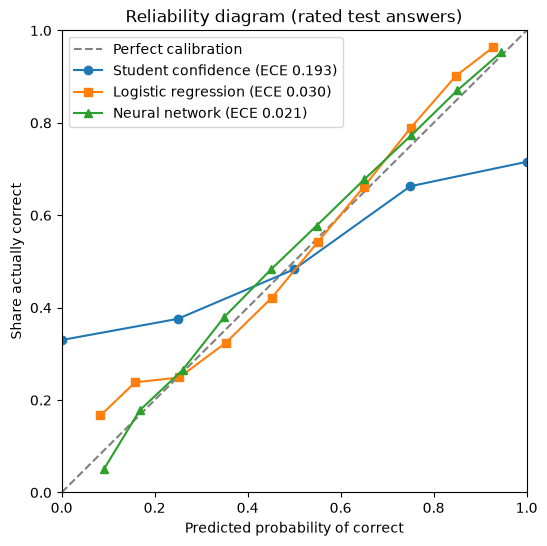

In [18]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")

for name, col, marker in [("Student confidence", "p_conf", "o"),
                          ("Logistic regression", "p_logreg", "s"),
                          ("Neural network", "p_nn", "^")]:
    t = calibration_table(rated["IsCorrect"], rated[col])
    e = ece(rated["IsCorrect"], rated[col])
    ax.plot(t["predicted"], t["actually_correct"], marker=marker, label=f"{name} (ECE {e:.3f})")

ax.set_xlabel("Predicted probability of correct")
ax.set_ylabel("Share actually correct")
ax.set_title("Reliability diagram (rated test answers)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="upper left")
fig.savefig(FIG / "reliability_diagram.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Confident but wrong
Among answers rated 100% confident, can the models find the ones that are actually wrong? These may be misconceptions that teachers would want to catch early.

In [23]:
sure = test[test["Confidence"] == 100].copy()     # only answers rated 100%
sure["wrong"] = 1 - sure["IsCorrect"]              # 1 = wrong, 0 = right

print("Answers rated 100%:", f"{len(sure):,}")
print("Share actually wrong:", round(sure["wrong"].mean() * 100, 1), "%")

# low probability of "correct" = likely wrong, so we flip the sign with a minus
print("Logistic regression AUC for finding wrong answers:", round(roc_auc_score(sure["wrong"], -sure["p_logreg"]), 3))
print("Neural network AUC for finding wrong answers:     ", round(roc_auc_score(sure["wrong"], -sure["p_nn"]), 3))

Answers rated 100%: 23,162
Share actually wrong: 28.4 %
Logistic regression AUC for finding wrong answers: 0.798
Neural network AUC for finding wrong answers:      0.8


**Takeaway:** Students said "100% sure" on 23,162 test answers, and 28.4% of them were wrong. The rating itself can't show which ones, because every rating is 100. 

Both models can: they find these confident mistakes with AUC 0.80. So the models can point teachers to answers that may hide a misconception.

### Teacher example
A teacher only has time to check 10%, 20% or 30% of the "100% sure" answers. If they check the ones the model trusts least, how many are really wrong?

In [ ]:
base_rate = sure["wrong"].mean() * 100         

rows = []
for share in [0.10, 0.20, 0.30]:
    k = int(share * len(sure))

    # without a model: random checks find mistakes at the normal rate
    rows.append({"teacher checks": f"{int(share * 100)}%",
                 "model": "Random (no model)",
                 "% really wrong": round(base_rate, 1),
                 "% of all mistakes found": round(share * 100, 1)})

    # with a model: check the answers the model trusts least
    for name, col in [("Logistic regression", "p_logreg"), ("Neural network", "p_nn")]:
        checked = sure.nsmallest(k, col)
        rows.append({"teacher checks": f"{int(share * 100)}%",
                     "model": name,
                     "% really wrong": round(checked["wrong"].mean() * 100, 1),
                     "% of all mistakes found": round(checked["wrong"].sum() / sure["wrong"].sum() * 100, 1)})

pd.DataFrame(rows)

,teacher checks,model,% really wrong,% of all mistakes found
0,10%,Random (no model),28.4,10.0
1,10%,Logistic regression,71.8,25.2
2,10%,Neural network,73.7,25.9
3,20%,Random (no model),28.4,20.0
4,20%,Logistic regression,63.9,45.0
5,20%,Neural network,64.1,45.1
6,30%,Random (no model),28.4,30.0
7,30%,Logistic regression,56.5,59.6
8,30%,Neural network,57.0,60.1


**Takeaway:** If a teacher checks only the 10% of "100% sure" answers that the model trusts least, about 3 out of 4 of them are really wrong (72–74%), compared with 28% at random. This finds about a quarter of all confident mistakes. Checking 30% finds 60% of them. Both models do this about equally well. A confident wrong answer may be a misconception or just a slip, and the data can't tell which.

## 5. Student groups
Do the models work equally well for every group? We compute AUC, accuracy and ECE separately per group on all test answers.
AUC is the main fairness check because it doesn't depend on how often a group is correct.
Gender "other" has only 164 test answers from 2 students, too few to evaluate.

In [24]:
groups = {
    "Female":               test["Gender"] == 1,
    "Male":                 test["Gender"] == 2,
    "Gender unspecified":   test["Gender"] == 0,
    "Free school meals":    test["PremiumPupil"] == 1,
    "No free school meals": test["PremiumPupil"] == 0,
}

rows = []
for group, mask in groups.items():
    part = test[mask]
    for name, col in [("Logistic regression", "p_logreg"), ("Neural network", "p_nn")]:
        rows.append({
            "group": group,
            "model": name,
            "answers": len(part),
            "students": part["UserId"].nunique(),
            "% correct": round(part["IsCorrect"].mean() * 100, 1),
            "mean prediction %": round(part[col].mean() * 100, 1),
            "AUC": round(roc_auc_score(part["IsCorrect"], part[col]), 4),
            "accuracy": round(accuracy_score(part["IsCorrect"], part[col] >= 0.5), 4),
            "ECE": round(ece(part["IsCorrect"], part[col]), 4),
        })

by_group = pd.DataFrame(rows)
by_group

,group,model,answers,students,% correct,mean prediction %,AUC,accuracy,ECE
0,Female,Logistic regression,71813,224,53.5,53.2,0.7711,0.7028,0.0353
1,Female,Neural network,71813,224,53.5,52.9,0.7748,0.7056,0.0061
2,Male,Logistic regression,69192,225,49.2,49.4,0.7601,0.7001,0.0436
3,Male,Neural network,69192,225,49.2,49.4,0.7623,0.7065,0.0063
4,Gender unspecified,Logistic regression,63663,288,57.2,57.2,0.7806,0.7114,0.0361
5,Gender unspecified,Neural network,63663,288,57.2,57.2,0.7838,0.7134,0.0067
6,Free school meals,Logistic regression,31951,97,43.1,44.2,0.7184,0.6806,0.0439
7,Free school meals,Neural network,31951,97,43.1,44.2,0.7220,0.6854,0.0115
8,No free school meals,Logistic regression,73356,220,54.8,54.1,0.7807,0.7108,0.0374
9,No free school meals,Neural network,73356,220,54.8,53.9,0.7836,0.7158,0.0080


**Takeaway:** The models work about equally well for female and male students (AUC gap about 0.01). But they work clearly worse for students on free school meals: AUC 0.722 vs. 0.784 for the neural network, and the same gap for logistic regression. For this group, the models also predict a little too high (44% vs. 43% really correct) and are a bit less calibrated. This result is based on only 97 test students, so the exact size of the gap is uncertain.

## 6. Bootstrap: are the differences real?
We resample **students** (not answers) with replacement 1,000 times and recompute each difference.
The middle 95% of the results is a 95% confidence interval. If it does not include 0, the difference is unlikely to be chance.
We resample students because answers from the same student are related.

In [25]:
test = test.reset_index(drop=True)          # row numbers 0, 1, 2, ...
test["p_conf"] = test["Confidence"] / 100   # rating -> probability


def differences(t):
    """The three differences we test, on the answers in table t."""
    rated = t[t["Confidence"].notna()]          # answers with a rating
    fsm = t[t["PremiumPupil"] == 1]             # free school meals
    not_fsm = t[t["PremiumPupil"] == 0]         # no free school meals

    nn_vs_lr = roc_auc_score(t["IsCorrect"], t["p_nn"]) - roc_auc_score(t["IsCorrect"], t["p_logreg"])
    nn_vs_conf = roc_auc_score(rated["IsCorrect"], rated["p_nn"]) - roc_auc_score(rated["IsCorrect"], rated["p_conf"])
    fsm_gap = roc_auc_score(not_fsm["IsCorrect"], not_fsm["p_nn"]) - roc_auc_score(fsm["IsCorrect"], fsm["p_nn"])

    return {"NN − LR (AUC)": nn_vs_lr,
            "NN − confidence (AUC, rated)": nn_vs_conf,
            "Free-school-meal gap (NN AUC)": fsm_gap}


observed = differences(test)        # on the real test set
observed

{'NN − LR (AUC)': 0.0030455638831096143,
 'NN − confidence (AUC, rated)': 0.15106045147049063,
 'Free-school-meal gap (NN AUC)': 0.061593808976289854}

In [ ]:
rows_of_student = test.groupby("UserId").indices     # student -> their row numbers
students = list(rows_of_student.keys())             # the 739 test students

rng = np.random.default_rng(42)                     # fixed seed: same result every run
results = []
for i in range(1000):
    picked = rng.choice(students, size=len(students), replace=True)   # pick 739 students, some twice
    rows = np.concatenate([rows_of_student[s] for s in picked])      # all their answers
    results.append(differences(test.loc[rows]))                      # compute again

boot = pd.DataFrame(results)

summary = pd.DataFrame({
    "observed": pd.Series(observed),
    "95% CI low": boot.quantile(0.025),
    "95% CI high": boot.quantile(0.975),
}).round(4)
summary

,observed,95% CI low,95% CI high
NN − LR (AUC),0.0048,0.0039,0.0056
"NN − confidence (AUC, rated)",0.1554,0.1396,0.1731
FSM gap (NN AUC: not FSM − FSM),0.0629,0.0350,0.0908


**Takeaway:** All three differences are real (no 95% interval includes 0).

The neural network beats logistic regression, but only by 0.004–0.006 AUC, so in practice the two are nearly equal.

Both models beat student confidence by a large margin (0.140–0.173 AUC).

The free-school-meal gap is real but uncertain (0.035–0.091), because only 97 test students have free school meals. The validation gap (0.045) falls inside this interval.